In [77]:
# import library
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sqlite3


In [78]:
# import databases..

In [79]:

conn = sqlite3.connect('customer_churn.db')

sql_query = '''
SELECT name
FROM sqlite_master
WHERE type = 'table'
'''
tables = pd.read_sql(sql_query, conn)

# create dataframe for each table
for table_name in tables['name']:
 df = pd.read_sql(f" SELECT * from {table_name}",conn)
 globals()[f"df_{table_name}"] =df
 print(f"created_dataframe : df_{table_name}")




created_dataframe : df_db_customer
created_dataframe : df_db_subscription
created_dataframe : df_db_support


In [80]:

import sqlite3
import pandas as pd

# Reconnect to the database
conn = sqlite3.connect('customer_churn.db')

# Get all table names
query = """
SELECT name
FROM sqlite_master
WHERE type = 'table'
"""

tables = pd.read_sql(query, conn)

# Display table names and their columns
for table_name in tables['name']:
    print(f"\nTable Name: {table_name}")

    query = f'PRAGMA table_info("{table_name}")'
    columns = pd.read_sql(query, conn)

    print("Column Names:", columns['name'].tolist())



Table Name: db_customer
Column Names: ['customerid', 'name', 'country', 'state', 'gender', 'dob', 'interests', 'pincode']

Table Name: db_subscription
Column Names: ['customerid', 'subscription_start_date', 'subscription_type', 'renewal_date', 'plan_type', 'contract_type', 'cancellation_date', 'cancellation_reason', 'monthly_charges', 'cltv', 'churn_score']

Table Name: db_support
Column Names: ['customerid', 'complaint_date', 'escalations', 'csat_score', 'col_1', 'comment']


In [81]:
# Data cleaning..

In [82]:
df_db_customer.head()
df_db_customer.tail()

,customerid,name,country,state,gender,dob,interests,pincode
16,0020-JDNXP,rikim,India,Meghalaya,Female,1994-08-19 00:00:00,NaN,None
17,0021-IKXGC,vishakha,India,Rajasthan,Female,2000-09-02 00:00:00,NaN,None
18,0022-TCJCI,raghvendra,India,Telangana,Male,1983-12-30 00:00:00,NaN,None
19,0023-HGHWL,rishabh,India,Uttar Pradesh,Men,1991-05-14 00:00:00,NaN,None
20,0023-UYUPN,sudevi,India,Maharashtra,Women,1977-10-06 00:00:00,NaN,None


In [83]:
df_db_customer.info()

<class 'pandas.DataFrame'>
RangeIndex: 21 entries, 0 to 20
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   customerid  21 non-null     str   
 1   name        21 non-null     str   
 2   country     18 non-null     str   
 3   state       21 non-null     str   
 4   gender      21 non-null     str   
 5   dob         21 non-null     str   
 6   interests   4 non-null      str   
 7   pincode     0 non-null      object
dtypes: object(1), str(7)
memory usage: 1.4+ KB


In [84]:
# Imortant point to clean the data
# a. drop column interests and pincode 
# b. fix country column
# c. Rename name into customer_name 
# d. change data type = dob
# e. data standardization - gender

In [85]:
# first rename..

df_db_customer.rename(columns = {"name" : "customer_name"}, inplace = True)

In [86]:
df_db_customer

,customerid,customer_name,country,state,gender,dob,interests,pincode
0,0002-ORFBO,keshav,India,Maharashtra,Male,1982-04-12 00:00:00,travel,None
1,0003-MKNFE,raghav,India,Karnataka,Male,1995-11-23 00:00:00,NaN,None
2,0004-TLHLJ,lalita,India,Delhi,Female,1978-02-15 00:00:00,movie,None
3,0011-IGKFF,mohan,India,Nagaland,Male,2001-08-30 00:00:00,NaN,None
4,0013-EXCHZ,mira,India,Delhi,Female,1990-05-05 00:00:00,drama,None
5,0013-MHZWF,durga,NaN,Delhi,Women,1988-12-10 00:00:00,NaN,None
6,0013-SMEOE,mina,India,Meghalaya,Female,1976-09-21 00:00:00,NaN,None
7,0014-BMAQU,madan,India,Rajasthan,Male,1999-03-14 00:00:00,NaN,None
8,0015-UOCOJ,maya,NaN,Kathmandu,Women,1985-07-07 00:00:00,NaN,None
9,0016-QLJIS,arjun,Nepal,Kathmandu,Male,1993-10-29 00:00:00,NaN,None


In [87]:
#  drop the columns..

#df_db_customer.drop(df_db_customer.columns[-2:], axis = 1 , inplace = 1) 
df_db_customer.drop(columns = ['interests' ,'pincode'], inplace = True)

In [88]:
df_db_customer

,customerid,customer_name,country,state,gender,dob
0,0002-ORFBO,keshav,India,Maharashtra,Male,1982-04-12 00:00:00
1,0003-MKNFE,raghav,India,Karnataka,Male,1995-11-23 00:00:00
2,0004-TLHLJ,lalita,India,Delhi,Female,1978-02-15 00:00:00
3,0011-IGKFF,mohan,India,Nagaland,Male,2001-08-30 00:00:00
4,0013-EXCHZ,mira,India,Delhi,Female,1990-05-05 00:00:00
5,0013-MHZWF,durga,NaN,Delhi,Women,1988-12-10 00:00:00
6,0013-SMEOE,mina,India,Meghalaya,Female,1976-09-21 00:00:00
7,0014-BMAQU,madan,India,Rajasthan,Male,1999-03-14 00:00:00
8,0015-UOCOJ,maya,NaN,Kathmandu,Women,1985-07-07 00:00:00
9,0016-QLJIS,arjun,Nepal,Kathmandu,Male,1993-10-29 00:00:00


In [89]:
df_db_customer.info()

<class 'pandas.DataFrame'>
RangeIndex: 21 entries, 0 to 20
Data columns (total 6 columns):
 #   Column         Non-Null Count  Dtype
---  ------         --------------  -----
 0   customerid     21 non-null     str  
 1   customer_name  21 non-null     str  
 2   country        18 non-null     str  
 3   state          21 non-null     str  
 4   gender         21 non-null     str  
 5   dob            21 non-null     str  
dtypes: str(6)
memory usage: 1.1 KB


In [90]:
# change the datatype...

df_db_customer['dob'] = pd.to_datetime(
    df_db_customer['dob']
)

In [91]:
df_db_customer.info()

<class 'pandas.DataFrame'>
RangeIndex: 21 entries, 0 to 20
Data columns (total 6 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   customerid     21 non-null     str           
 1   customer_name  21 non-null     str           
 2   country        18 non-null     str           
 3   state          21 non-null     str           
 4   gender         21 non-null     str           
 5   dob            21 non-null     datetime64[us]
dtypes: datetime64[us](1), str(5)
memory usage: 1.1 KB


In [92]:
# data genderazation genderr..

df_db_customer['gender'].unique()
df_db_customer['gender'] = df_db_customer['gender'].replace({
    'Men': 'Male',
    'Women': 'Female'
})                                 


In [93]:
df_db_customer['gender'].unique()

<StringArray>
['Male', 'Female']
Length: 2, dtype: str

In [94]:
# missing values country

df_db_customer[df_db_customer['country'].isna()]

,customerid,customer_name,country,state,gender,dob
5,0013-MHZWF,durga,NaN,Delhi,Female,1988-12-10
8,0015-UOCOJ,maya,NaN,Kathmandu,Female,1985-07-07
12,0018-NYROU,chitra,NaN,Telangana,Female,2004-12-01


In [95]:
df_db_customer['country'].fillna(0)

0     India
1     India
2     India
3     India
4     India
5         0
6     India
7     India
8         0
9     Nepal
10    India
11    India
12        0
13    India
14    India
15    India
16    India
17    India
18    India
19    India
20    India
Name: country, dtype: object

In [96]:
# df_db_customer[['country','state']]

state_country_mapping = df_db_customer.dropna(subset=['country']).set_index('state')['country'].to_dict()
df_db_customer['country'] = df_db_customer['country'].fillna(df_db_customer['state'].map(state_country_mapping))

In [97]:
 df_db_customer[['country','state']]

,country,state
0,India,Maharashtra
1,India,Karnataka
2,India,Delhi
3,India,Nagaland
4,India,Delhi
5,India,Delhi
6,India,Meghalaya
7,India,Rajasthan
8,Nepal,Kathmandu
9,Nepal,Kathmandu


In [98]:
# clean our 2nd table..


In [99]:
df_db_subscription.head()


,customerid,subscription_start_date,subscription_type,renewal_date,plan_type,contract_type,cancellation_date,cancellation_reason,monthly_charges,cltv,churn_score
0,0002-ORFBO,2021-03-15,Refferal,2025-03-15,Standard,Annual,NaN,NaN,13.99,627,12
1,0003-MKNFE,2020-08-01,Paid,2024-08-01,Premium,Annual,2024-09-10,Switched to competitor,12.99,1150,91
2,0004-TLHLJ,2022-11-20,Organic,2025-11-20,Basic,Monthly,NaN,NaN,6.99,210,34
3,0011-IGKFF,2019-05-10,Paid,2025-05-10,Premium,Annual,NaN,NaN,22.99,1725,8
4,0013-EXCHZ,2023-01-05,Refferal,2024-01-05,Standard,Monthly,2024-02-28,Too expensive,13.99,195,88


In [100]:
df_db_subscription.info()

<class 'pandas.DataFrame'>
RangeIndex: 21 entries, 0 to 20
Data columns (total 11 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   customerid               21 non-null     str    
 1   subscription_start_date  21 non-null     str    
 2   subscription_type        21 non-null     str    
 3   renewal_date             21 non-null     str    
 4   plan_type                21 non-null     str    
 5   contract_type            21 non-null     str    
 6   cancellation_date        6 non-null      str    
 7   cancellation_reason      6 non-null      str    
 8   monthly_charges          21 non-null     float64
 9   cltv                     21 non-null     int64  
 10  churn_score              21 non-null     int64  
dtypes: float64(1), int64(2), str(8)
memory usage: 1.9 KB


In [101]:
# fix datatypes...


date_col =['subscription_start_date', 'renewal_date', 'cancellation_date']
df_db_subscription[date_col] = df_db_subscription[date_col].apply(pd.to_datetime)
df_db_subscription.info()


<class 'pandas.DataFrame'>
RangeIndex: 21 entries, 0 to 20
Data columns (total 11 columns):
 #   Column                   Non-Null Count  Dtype         
---  ------                   --------------  -----         
 0   customerid               21 non-null     str           
 1   subscription_start_date  21 non-null     datetime64[us]
 2   subscription_type        21 non-null     str           
 3   renewal_date             21 non-null     datetime64[us]
 4   plan_type                21 non-null     str           
 5   contract_type            21 non-null     str           
 6   cancellation_date        6 non-null      datetime64[us]
 7   cancellation_reason      6 non-null      str           
 8   monthly_charges          21 non-null     float64       
 9   cltv                     21 non-null     int64         
 10  churn_score              21 non-null     int64         
dtypes: datetime64[us](3), float64(1), int64(2), str(5)
memory usage: 1.9 KB


In [102]:
# clean 3rd tabel..

In [103]:
df_db_support.head()

,customerid,complaint_date,escalations,csat_score,col_1,comment
0,0003-MKNFE,2024-08-28 00:00:00,N,60,None,service issue
1,0003-MKNFE,2024-08-28 00:00:00,Y,10,None,demaned refund
2,0013-EXCHZ,2024-01-20 00:00:00,Y,20,None,NaN
3,0013-MHZWF,2025-03-18 00:00:00,N,90,None,guidance to renew
4,0013-SMEOE,2024-11-01 00:00:00,N,30,None,NaN


In [104]:
df_db_support.info()

<class 'pandas.DataFrame'>
RangeIndex: 9 entries, 0 to 8
Data columns (total 6 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   customerid      9 non-null      str   
 1   complaint_date  9 non-null      str   
 2   escalations     9 non-null      str   
 3   csat_score      9 non-null      int64 
 4   col_1           0 non-null      object
 5   comment         4 non-null      str   
dtypes: int64(1), object(1), str(4)
memory usage: 564.0+ bytes


In [105]:
# fix datatype , remove last 2 columns.

df_db_support['complaint_date'] = pd.to_datetime(df_db_support['complaint_date'])
df_db_support.drop(columns = ['col_1','comment'],inplace = True)


In [106]:
df_db_support.info()

<class 'pandas.DataFrame'>
RangeIndex: 9 entries, 0 to 8
Data columns (total 4 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   customerid      9 non-null      str           
 1   complaint_date  9 non-null      datetime64[us]
 2   escalations     9 non-null      str           
 3   csat_score      9 non-null      int64         
dtypes: datetime64[us](1), int64(1), str(2)
memory usage: 420.0 bytes


In [107]:
#We had fix all the data cleaning  process of all tables..

In [108]:
# Feature egenering and  analysis the data

In [109]:
df_db_subscription.head(3)

,customerid,subscription_start_date,subscription_type,renewal_date,plan_type,contract_type,cancellation_date,cancellation_reason,monthly_charges,cltv,churn_score
0,0002-ORFBO,2021-03-15,Refferal,2025-03-15,Standard,Annual,NaT,NaN,13.99,627,12
1,0003-MKNFE,2020-08-01,Paid,2024-08-01,Premium,Annual,2024-09-10,Switched to competitor,12.99,1150,91
2,0004-TLHLJ,2022-11-20,Organic,2025-11-20,Basic,Monthly,NaT,NaN,6.99,210,34


In [176]:
# create churn flag. To know the customer churn rate.

df_db_subscription['churn_flag'] = np.where(df_db_subscription['cancellation_date'].notna(),1,0)

In [111]:
# create and modify suppoort table beacuse data is mismatch in support table and remove duplicates..


df_db_support['complaint_count'] = df_db_support.groupby('customerid')['customerid'].transform('count')
df_db_support = df_db_support.sort_values('complaint_date').drop_duplicates('customerid', keep = 'last')

In [112]:
# we will join all the tables..

df = (df_db_subscription
                 .merge(df_db_customer , on ='customerid' , how ='left')
                 .merge(df_db_support , on ='customerid' , how ='left'))

In [113]:
df.shape

(21, 21)

In [114]:
df_db_subscription.shape

(21, 12)

In [115]:
df_db_customer.shape

(21, 6)

In [116]:
df_db_support.shape

(7, 5)

In [117]:
df

,customerid,subscription_start_date,subscription_type,renewal_date,plan_type,contract_type,cancellation_date,cancellation_reason,monthly_charges,cltv,...,churn_flag,customer_name,country,state,gender,dob,complaint_date,escalations,csat_score,complaint_count
0,0002-ORFBO,2021-03-15,Refferal,2025-03-15,Standard,Annual,NaT,NaN,13.99,627,...,0,keshav,India,Maharashtra,Male,1982-04-12,NaT,NaN,NaN,NaN
1,0003-MKNFE,2020-08-01,Paid,2024-08-01,Premium,Annual,2024-09-10,Switched to competitor,12.99,1150,...,1,raghav,India,Karnataka,Male,1995-11-23,2024-08-28,Y,10.0,2.0
2,0004-TLHLJ,2022-11-20,Organic,2025-11-20,Basic,Monthly,NaT,NaN,6.99,210,...,0,lalita,India,Delhi,Female,1978-02-15,NaT,NaN,NaN,NaN
3,0011-IGKFF,2019-05-10,Paid,2025-05-10,Premium,Annual,NaT,NaN,22.99,1725,...,0,mohan,India,Nagaland,Male,2001-08-30,NaT,NaN,NaN,NaN
4,0013-EXCHZ,2023-01-05,Refferal,2024-01-05,Standard,Monthly,2024-02-28,Too expensive,13.99,195,...,1,mira,India,Delhi,Female,1990-05-05,2024-01-20,Y,20.0,1.0
5,0013-MHZWF,2022-06-18,Paid,2025-06-18,Standard,Annual,NaT,NaN,17.99,720,...,0,durga,India,Delhi,Female,1988-12-10,2025-03-18,N,90.0,1.0
6,0013-SMEOE,2021-09-30,Refferal,2024-09-30,Basic,Monthly,2024-11-15,Not enough content,8.99,230,...,1,mina,India,Meghalaya,Female,1976-09-21,2024-11-01,N,30.0,1.0
7,0014-BMAQU,2020-02-14,Organic,2025-02-14,Premium,Annual,NaT,NaN,22.99,1840,...,0,madan,India,Rajasthan,Male,1999-03-14,NaT,NaN,NaN,NaN
8,0015-UOCOJ,2023-07-22,Organic,2024-07-22,Standard,Monthly,NaT,NaN,13.99,240,...,0,maya,Nepal,Kathmandu,Female,1985-07-07,NaT,NaN,NaN,NaN
9,0016-QLJIS,2022-04-03,Organic,2025-04-03,Basic,Annual,NaT,NaN,6.99,335,...,0,arjun,Nepal,Kathmandu,Male,1993-10-29,NaT,NaN,NaN,NaN


In [118]:
# exported data in excel in csv format.

df.to_csv('expoert_churn_dataa.csv' , index = False)

In [119]:
# data analyis..

In [120]:
df.columns

Index(['customerid', 'subscription_start_date', 'subscription_type',
       'renewal_date', 'plan_type', 'contract_type', 'cancellation_date',
       'cancellation_reason', 'monthly_charges', 'cltv', 'churn_score',
       'churn_flag', 'customer_name', 'country', 'state', 'gender', 'dob',
       'complaint_date', 'escalations', 'csat_score', 'complaint_count'],
      dtype='str')

In [121]:
# 1. find the churn rate 
churn_rate = df['churn_flag'].mean()*100
 print('churn_rate = ' ,round(churn_rate,2) ,"%")

churn_rate =  28.57 %


In [122]:
# 2. retaintion rate..
retaintion_rate = 100 - churn_rate
print('retaintion_rate = ' ,round(retaintion_rate,2) ,"%")


retaintion_rate =  71.43 %


In [123]:
#3.  churn by plan type..

churn_by_plan = (df.groupby('plan_type')['churn_flag'].mean().mul(100).round(2).reset_index(name = 'churn_rate_prtg'))
print(churn_by_plan)

  plan_type  churn_rate_prtg
0     Basic            60.00
1   Premium            14.29
2  Standard            22.22


In [124]:
print(df.columns.tolist())

['customerid', 'subscription_start_date', 'subscription_type', 'renewal_date', 'plan_type', 'contract_type', 'cancellation_date', 'cancellation_reason', 'monthly_charges', 'cltv', 'churn_score', 'churn_flag', 'customer_name', 'country', 'state', 'gender', 'dob', 'complaint_date', 'escalations', 'csat_score', 'complaint_count']


In [129]:
#4.  arpu - average revenue per user

Arpu = df['monthly_charges'].mean()
print('Arpu is = ', round(Arpu,2))
#df.columns


Arpu is =  18.85


In [137]:
# 5. average customeer tenure
# count the day user has used our service - cancelattaionn date and current date

today = pd.Timestamp.today()

df['Tenure_days'] = np.where(
    df['cancellation_date'].notna(),
    (df['cancellation_date'] - df['subscription_start_date']).dt.days,
     (today - df['subscription_start_date']).dt.days
  )
avg_tenure = df['Tenure_days'].mean()
print('avg_tenure_days = ' , round(avg_tenure,0))

avg_tenure_days =  1569.0


In [141]:
# 6. renenue at risk - revenue lost for churn users.

revenue_risk = df.loc[df['churn_flag'] == 1,'monthly_charges'].sum()
print('revenue at risk rupees k =',revenue_risk)

revenue at risk rupees k = 73.94


In [143]:
#7. find escalation rate
escalation_rate = (df['escalations']=='Y').mean() * 100

print("Escalation Rate:", round(escalation_rate, 2), "%")

Escalation Rate: 19.05 %


In [145]:
#8. average complaint  per  user
avg_complaint_per_user = df['complaint_count'].sum() / df['customerid'].nunique()

print("Average Complaint per User:", round(avg_complaint_per_user, 2))

Average Complaint per User: 0.43


In [190]:

# 9. Correlation Escalation vs Churn

# Y = 1, N = 0
corr_df = df[['escalations', 'churn_flag']].dropna().copy()

corr_df['escalations'] = corr_df['escalations'].map({
    'Y': 1,
    'N': 0
})

correlation = corr_df['escalations'].corr(
    corr_df['churn_flag']
)

print("Correlation between escalation vs churn is =", round(correlation, 2))


Correlation between escalation vs churn is = 0.47


In [191]:
# find the churn riskk using exc column

df['churn_risk'] = np.where(
    df['churn_score'] < 50, 'Low',
    np.where(df['churn_score'] <= 70, 'Medium', 'High')
)

print(df[['churn_score', 'churn_risk']].head(10))


   churn_score churn_risk
0           12        Low
1           91       High
2           34        Low
3            8        Low
4           88       High
5           22        Low
6           79       High
7            5        Low
8           34        Low
9           41        Low


In [ ]:
# visualization...

In [197]:
df.columns

Index(['customerid', 'subscription_start_date', 'subscription_type',
       'renewal_date', 'plan_type', 'contract_type', 'cancellation_date',
       'cancellation_reason', 'monthly_charges', 'cltv', 'churn_score',
       'customer_name', 'country', 'state', 'gender', 'dob', 'complaint_date',
       'csat_score', 'complaint_count', 'Tenure_days', 'churn_flag',
       'escalations', 'churn_risk'],
      dtype='str')

In [192]:
df_visual = df.copy()

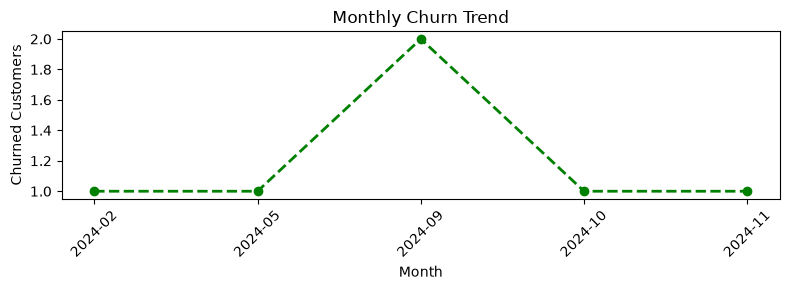

In [204]:
# 1. find monnthly churn trend

# Cancellation date se month create karege
df_visual['cancellation_month'] = ( 
    df_visual['cancellation_date'].dt.to_period('M')
)

# Sirf churned customers ko month-wise count krege
churn_trend = (
    df_visual[df_visual['churn_flag'] == 1]
    .groupby('cancellation_month')
    .size()
)

# Line chart banage
plt.figure(figsize=(8, 3))

plt.plot(
    churn_trend.index.astype(str),
    churn_trend.values,
    color='green',
    marker='o',
    linestyle='dashed',
    linewidth=2,
    markersize=6
)

plt.title('Monthly Churn Trend')
plt.xlabel('Month')
plt.ylabel('Churned Customers')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


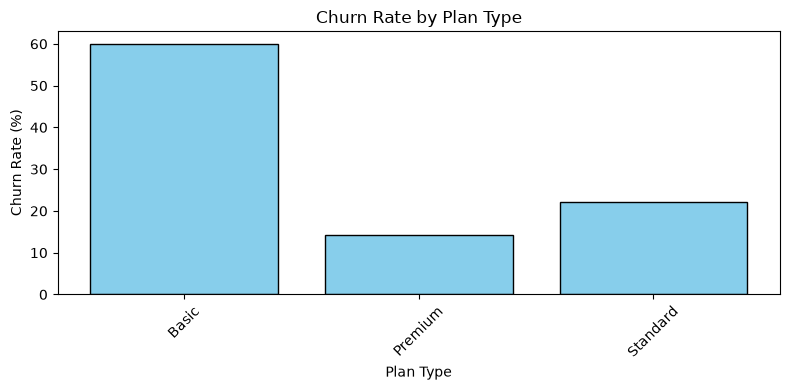

In [202]:
# 2. churn by plan type

# Plan type ke hisaab se churn rate calculate krege
churn_by_plan = (
    df_visual.groupby('plan_type')['churn_flag']
    .mean()
    .mul(100)
    .round(2)
)

# Bar chart banaege
plt.figure(figsize=(8, 4))

plt.bar(
    churn_by_plan.index,
    churn_by_plan.values,
    color='skyblue',
    edgecolor='black'
)

plt.title('Churn Rate by Plan Type')
plt.xlabel('Plan Type')
plt.ylabel('Churn Rate (%)')

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


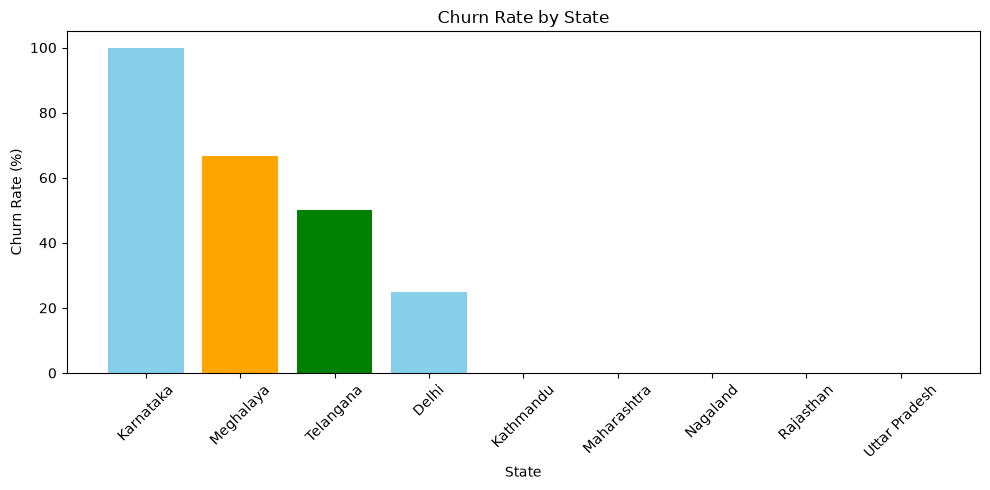

In [205]:
#3. churn by state

churn_by_state = (
    df.groupby('state')['churn_flag']
    .mean()
    .mul(100)
    .round(2)
    .sort_values(ascending=False)
)

# 3 colors repeat honge
colors = ['skyblue', 'orange', 'green']

plt.figure(figsize=(10, 5))

plt.bar(
    churn_by_state.index,
    churn_by_state.values,
    color=[colors[i % 3] for i in range(len(churn_by_state))]
)

plt.title('Churn Rate by State')
plt.xlabel('State')
plt.ylabel('Churn Rate (%)')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


In [ ]:
# vizualization on seaborn

In [206]:
# encoding - convert str to numeric so that we can find corr between features
df_visual.columns

Index(['customerid', 'subscription_start_date', 'subscription_type',
       'renewal_date', 'plan_type', 'contract_type', 'cancellation_date',
       'cancellation_reason', 'monthly_charges', 'cltv', 'churn_score',
       'customer_name', 'country', 'state', 'gender', 'dob', 'complaint_date',
       'csat_score', 'complaint_count', 'Tenure_days', 'churn_flag',
       'escalations', 'churn_risk', 'cancellation_month'],
      dtype='str')

In [207]:
df_visual[['plan_type', 'contract_type', 'churn_score', 'churn_flag', 'churn_risk', 'escalations']].head()

,plan_type,contract_type,churn_score,churn_flag,churn_risk,escalations
0,Standard,Annual,12,0,Low,NaN
1,Premium,Annual,91,1,High,Y
2,Basic,Monthly,34,0,Low,NaN
3,Premium,Annual,8,0,Low,NaN
4,Standard,Monthly,88,1,High,Y


In [208]:
# remove warnings
import warnings
warnings.filterwarnings("ignore")

In [211]:
# incorrect method of encoding - as numbers are not assigned based on priority
df_encoded = df_visual[['plan_type', 'contract_type', 'churn_score', 'churn_flag', 'churn_risk', 'escalations']]

categorial_cols = ['plan_type', 'contract_type', 'churn_risk']

for col in categorial_cols:
    df_encoded[col] = df_encoded[col].astype('category').cat.codes

In [213]:
print('plan_type :', df_visual['plan_type'].unique())
print('contract_type :', df_visual['contract_type'].unique())
print('churn_risk :', df_visual['churn_risk'].unique())

plan_type : <StringArray>
['Standard', 'Premium', 'Basic']
Length: 3, dtype: str
contract_type : <StringArray>
['Annual', 'Monthly']
Length: 2, dtype: str
churn_risk : <StringArray>
['Low', 'High', 'Medium']
Length: 3, dtype: str


In [214]:
# Correct method of encoding - based on priority
df_encoded = df_visual[['plan_type', 'contract_type', 'churn_score', 'churn_flag', 'churn_risk', 'escalations']]

order_mappings = {
    'plan_type' : ['Basic', 'Standard', 'Premium'],
    'contract_type' : ['Monthly', 'Annual'],
    'churn_risk': ['low', 'med', 'high']
    }

for col, order in order_mappings.items():
    df_encoded[col] = pd.Categorical(df_encoded[col].astype('category'), categories=order, ordered=True).codes

In [215]:
df_visual[['plan_type', 'contract_type', 'churn_score', 'churn_flag', 'churn_risk', 'escalations']].head()

,plan_type,contract_type,churn_score,churn_flag,churn_risk,escalations
0,Standard,Annual,12,0,Low,NaN
1,Premium,Annual,91,1,High,Y
2,Basic,Monthly,34,0,Low,NaN
3,Premium,Annual,8,0,Low,NaN
4,Standard,Monthly,88,1,High,Y


In [216]:
df_encoded.head()

,plan_type,contract_type,churn_score,churn_flag,churn_risk,escalations
0,1,1,12,0,-1,NaN
1,2,1,91,1,-1,Y
2,0,0,34,0,-1,NaN
3,2,1,8,0,-1,NaN
4,1,0,88,1,-1,Y


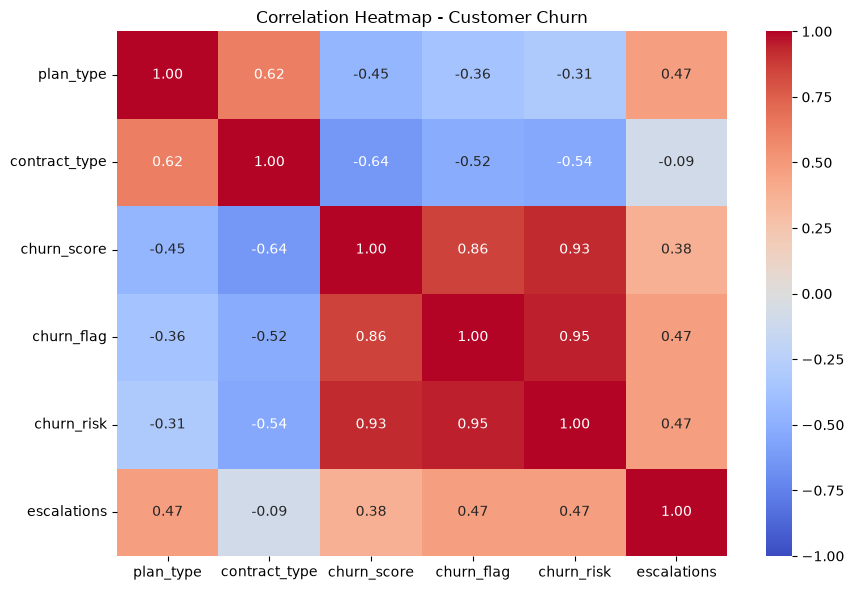

In [219]:
df_encoded = df_visual[
    ['plan_type', 'contract_type', 'churn_score',
     'churn_flag', 'churn_risk', 'escalations']
].copy()

# Categories ko correct numeric values mein encode
order_mappings = {
    'plan_type': ['Basic', 'Standard', 'Premium'],
    'contract_type': ['Monthly', 'Annual'],
    'churn_risk': ['Low', 'Medium', 'High']
}

for col, order in order_mappings.items():
    df_encoded[col] = pd.Categorical(
        df_encoded[col],
        categories=order,
        ordered=True
    ).codes

# Escalations: Y = 1, N = 0
df_encoded['escalations'] = (
    df_encoded['escalations']
    .map({'Y': 1, 'N': 0})
)

# Correlation ke liye missing values wali rows hataii
corr_matrix = df_encoded.corr()

# Heatmap
plt.figure(figsize=(9, 6))
sns.heatmap(
    corr_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    vmin=-1,
    vmax=1
)

plt.title('Correlation Heatmap - Customer Churn')
plt.tight_layout()
plt.show()


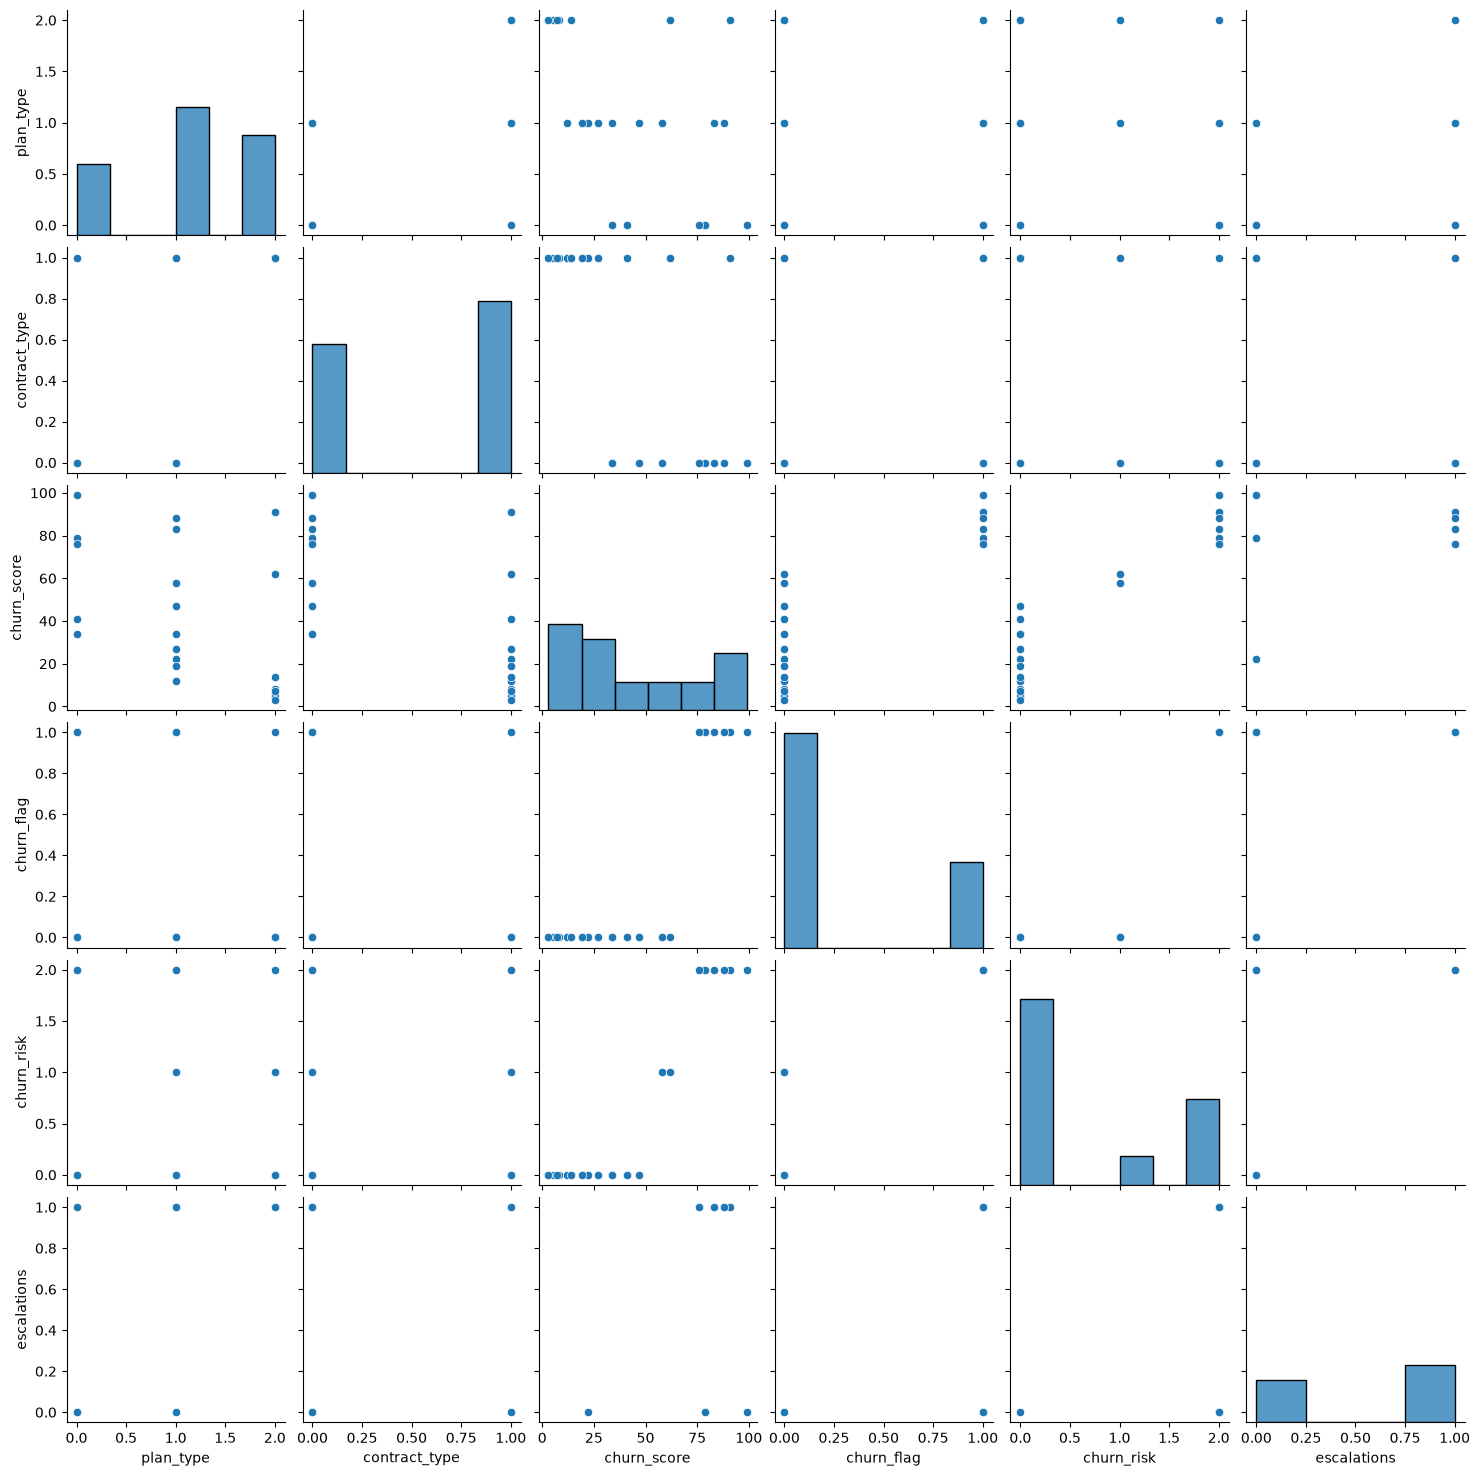

In [220]:
# pairplot

sns.pairplot(df_encoded)

In [221]:
# pivot table using multiple cols and agg type

pd.pivot_table(
    df_visual,
    index='plan_type',
    values=['monthly_charges', 'customerid', 'churn_flag'],
    aggfunc = {
        'monthly_charges' : 'sum',
        'customerid' : 'nunique',
        'churn_flag' : 'mean'
    }
)

,churn_flag,customerid,monthly_charges
plan_type,,,
Basic,0.600000,5,52.95
Premium,0.142857,7,218.93
Standard,0.222222,9,123.91


In [ ]:
# project completed
